# Raw data analysis

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load
df = pd.read_csv("../data/raw/github_repositories.csv")
print(df.shape)
df.head()

(1000, 24)


,name,full_name,stars,forks,watchers,open_issues,language,size,created_at,updated_at,...,has_wiki,has_pages,is_fork,archived,commits,contributors,releases,open_pull_requests,subscribers_count,network_count
0,build-your-own-x,codecrafters-io/build-your-own-x,500552,47463,500552,479,Markdown,1201,2018-05-09T12:03:18Z,2026-05-11T16:01:16Z,...,False,False,False,False,611,140.0,0,226.0,6677,47463
1,awesome,sindresorhus/awesome,465232,34902,465232,73,NaN,1561,2014-07-11T13:42:37Z,2026-05-11T16:01:32Z,...,False,True,False,False,1201,674.0,0,56.0,8183,34902
2,freeCodeCamp,freeCodeCamp/freeCodeCamp,444500,44515,444500,185,TypeScript,572816,2014-12-24T17:49:19Z,2026-05-11T15:51:03Z,...,False,False,False,False,41568,6450.0,0,74.0,8550,44515
3,public-apis,public-apis/public-apis,434098,47524,434098,1312,Python,5349,2016-03-20T23:49:42Z,2026-05-11T16:01:51Z,...,False,False,False,False,4668,1437.0,0,1305.0,4601,47525
4,free-programming-books,EbookFoundation/free-programming-books,388075,66281,388075,80,Python,21280,2013-10-11T06:50:37Z,2026-05-11T16:01:14Z,...,False,True,False,False,10081,3492.0,0,46.0,9795,66281


In [63]:
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nBasic stats:")
df[["stars", "forks", "watchers", "open_issues", "size", "commits"]].describe()

name                   object
full_name              object
stars                   int64
forks                   int64
watchers                int64
open_issues             int64
language               object
size                    int64
created_at             object
updated_at             object
description            object
homepage               object
license                object
topics                 object
has_wiki                 bool
has_pages                bool
is_fork                  bool
archived                 bool
commits                 int64
contributors          float64
releases                int64
open_pull_requests    float64
subscribers_count       int64
network_count           int64
dtype: object

Missing values:
name                    0
full_name               0
stars                   0
forks                   0
watchers                0
open_issues             0
language               95
size                    0
created_at              0
updated_at     

,stars,forks,watchers,open_issues,size,commits
count,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1.000000e+03
mean,61478.739000,9413.613000,61478.739000,840.039000,4.276105e+05,1.245041e+04
std,48943.403806,11502.667077,48943.403806,2312.431886,1.978110e+06,5.459400e+04
min,31097.000000,358.000000,31097.000000,0.000000,5.000000e+00,1.000000e+00
25%,36429.250000,3315.750000,36429.250000,60.000000,1.103975e+04,8.690000e+02
50%,45754.000000,6048.000000,45754.000000,248.500000,5.936250e+04,2.910500e+03
75%,66083.250000,10399.500000,66083.250000,736.250000,2.164162e+05,8.121000e+03
max,500552.000000,109841.000000,500552.000000,35993.000000,4.354393e+07,1.445074e+06


## Distrubution of the target

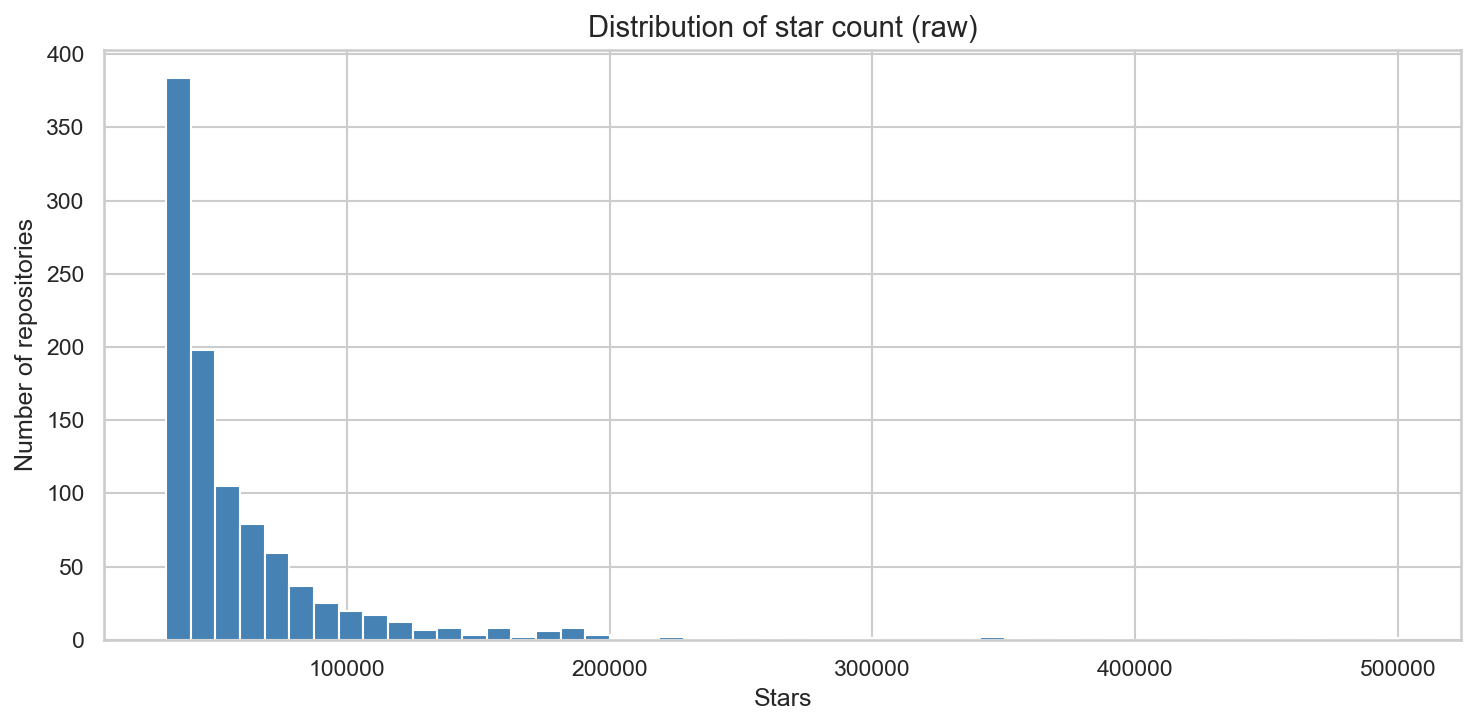

In [64]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["stars"], bins=50, color="steelblue", edgecolor="white")
ax.set_title("Distribution of star count (raw)", fontsize=14)
ax.set_xlabel("Stars")
ax.set_ylabel("Number of repositories")
plt.tight_layout()
plt.savefig("../notebooks/figures/stars_raw.png")
plt.show()

Log transform for the target

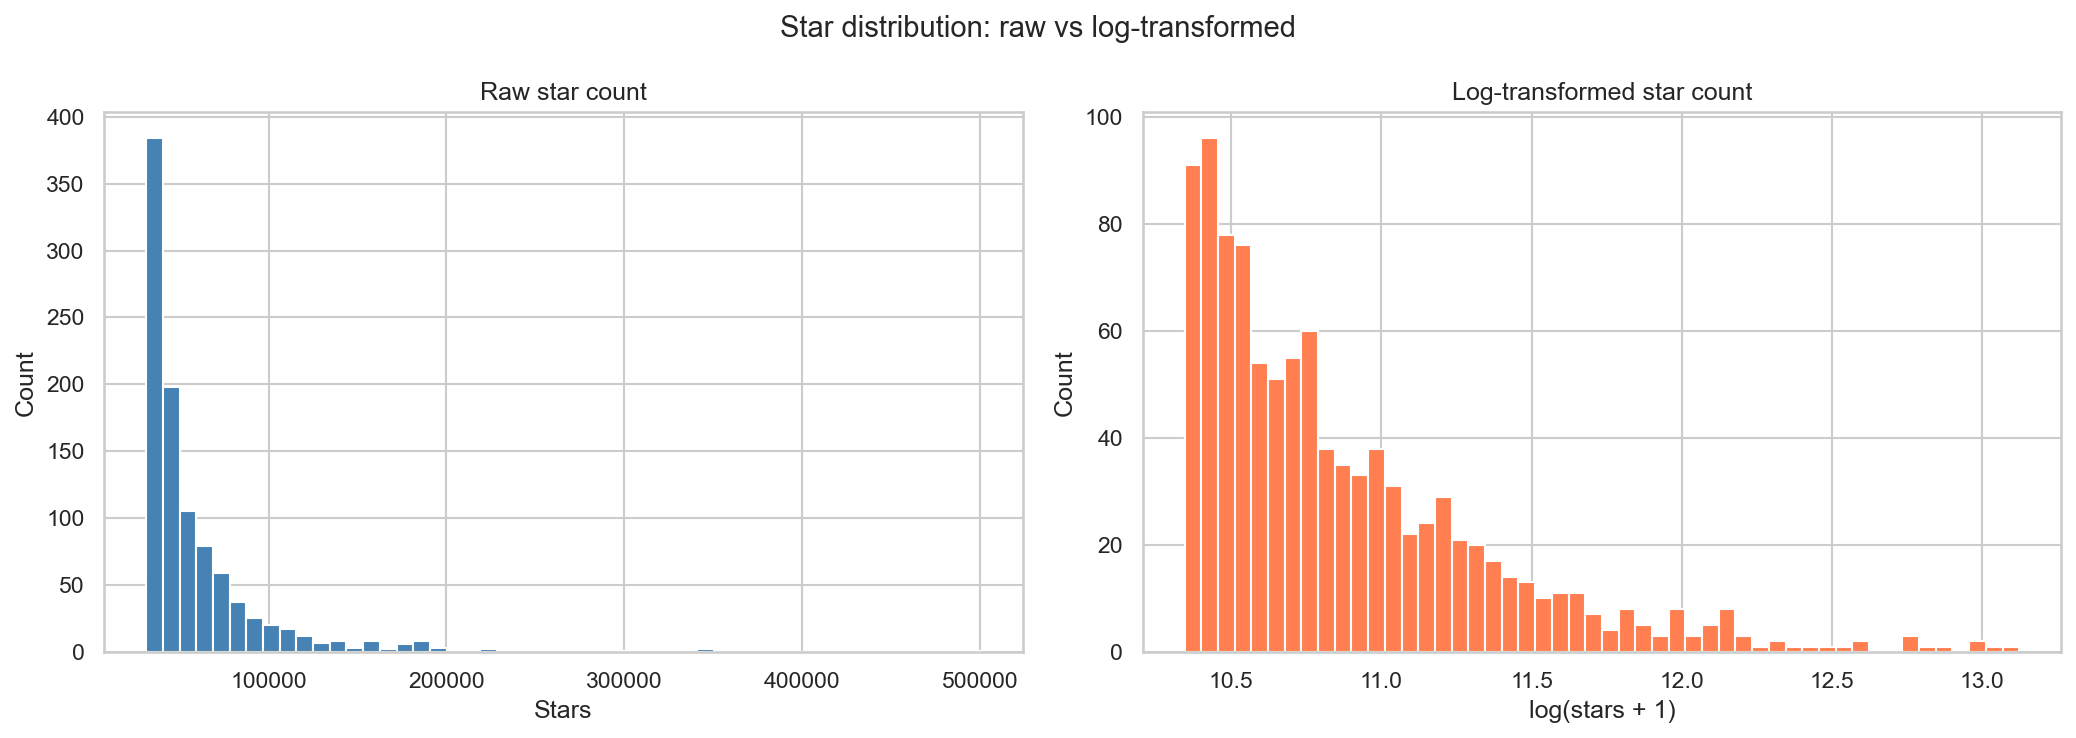

In [65]:
df["log_stars"] = np.log1p(df["stars"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw
axes[0].hist(df["stars"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Raw star count")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Count")

# Log transformed
axes[1].hist(df["log_stars"], bins=50, color="coral", edgecolor="white")
axes[1].set_title("Log-transformed star count")
axes[1].set_xlabel("log(stars + 1)")
axes[1].set_ylabel("Count")

plt.suptitle("Star distribution: raw vs log-transformed", fontsize=14)
plt.tight_layout()
plt.savefig("../notebooks/figures/stars_distribution.png")
plt.show()

## Correlation between features

In [66]:
mismatch = (df["watchers"] != df["stars"]).sum()
print(f"Rows where watchers != stars: {mismatch} out of {len(df)}")

Rows where watchers != stars: 0 out of 1000


Starts and watchers have 1-1 correlation, so watchers should be dropped (data leakeage)

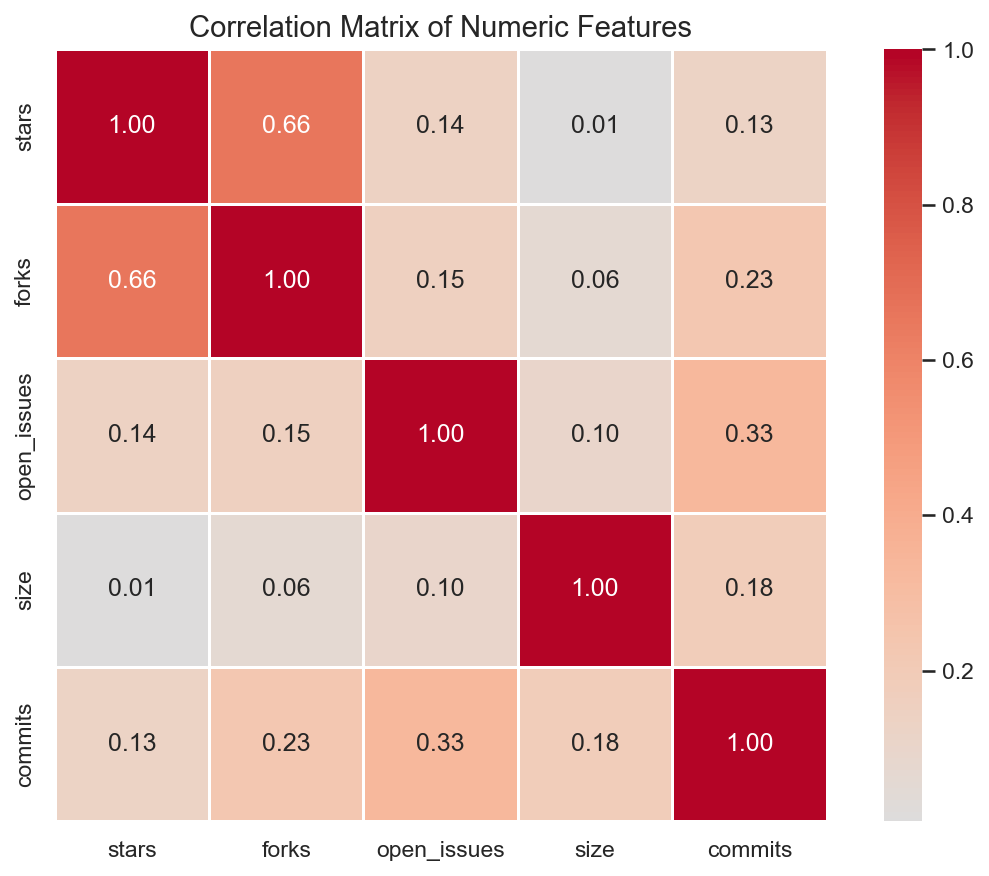

In [67]:
# Drop watchers and non-numeric columns
numeric_cols = ["stars", "forks", "open_issues", "size", "commits"]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,           
    fmt=".2f",            
    cmap="coolwarm",      
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)
ax.set_title("Correlation Matrix of Numeric Features", fontsize=14)
plt.tight_layout()
plt.savefig("../notebooks/figures/correlation_matrix.png")
plt.show()

## Language feature analysis

In [68]:
print(df["language"].value_counts().head(15))
print(f"\nNull languages: {df['language'].isnull().sum()}")
print(f"Total unique languages: {df['language'].nunique()}")

language
Python              211
TypeScript          171
JavaScript          109
Go                   77
Rust                 57
C++                  42
Java                 42
Shell                24
Jupyter Notebook     23
C                    21
HTML                 16
Ruby                 12
C#                   10
Swift                 9
Kotlin                9
Name: count, dtype: int64

Null languages: 95
Total unique languages: 42


In [69]:
# Define which languages get their own column
top_languages = [
    "Python", "TypeScript", "JavaScript", "Go", "Rust",
    "C++", "Java", "Shell", "Jupyter Notebook", "C",
    "HTML", "Ruby", "C#", "Swift", "Kotlin", "CSS"
]

# Fill nulls
df["language"] = df["language"].fillna("Unknown")

# Bucket rare languages
df["language_grouped"] = df["language"].apply(
    lambda x: x if x in top_languages else "Other"
)

# Verify
print(df["language_grouped"].value_counts())
print(f"\nTotal categories: {df['language_grouped'].nunique()}")

language_grouped
Python              211
TypeScript          171
Other               158
JavaScript          109
Go                   77
Rust                 57
Java                 42
C++                  42
Shell                24
Jupyter Notebook     23
C                    21
HTML                 16
Ruby                 12
C#                   10
Swift                 9
CSS                   9
Kotlin                9
Name: count, dtype: int64

Total categories: 17


Languages are going to get one-hot encoding

In [70]:
language_dummies = pd.get_dummies(df["language_grouped"], prefix="lang")

print(f"New columns created: {list(language_dummies.columns)}")
print(f"Shape: {language_dummies.shape}")
language_dummies.head()

New columns created: ['lang_C', 'lang_C#', 'lang_C++', 'lang_CSS', 'lang_Go', 'lang_HTML', 'lang_Java', 'lang_JavaScript', 'lang_Jupyter Notebook', 'lang_Kotlin', 'lang_Other', 'lang_Python', 'lang_Ruby', 'lang_Rust', 'lang_Shell', 'lang_Swift', 'lang_TypeScript']
Shape: (1000, 17)


,lang_C,lang_C#,lang_C++,lang_CSS,lang_Go,lang_HTML,lang_Java,lang_JavaScript,lang_Jupyter Notebook,lang_Kotlin,lang_Other,lang_Python,lang_Ruby,lang_Rust,lang_Shell,lang_Swift,lang_TypeScript
0,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False


## Creation of new features from date columns and others

In [71]:
from datetime import datetime, timezone

# Convert to datetime
df["created_at"] = pd.to_datetime(df["created_at"])
df["updated_at"] = pd.to_datetime(df["updated_at"])

now = datetime.now(timezone.utc)

# New features
df["repo_age_days"] = (now - df["created_at"]).dt.days
df["days_since_last_update"] = (now - df["updated_at"]).dt.days
df["commits_per_day"] = df["commits"] / df["repo_age_days"]
df["fork_ratio"] = df["forks"] / (df["stars"] + 1)

# Sanity check
df[["repo_age_days", "days_since_last_update", "commits_per_day", "fork_ratio"]].describe()

,repo_age_days,days_since_last_update,commits_per_day,fork_ratio
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,2867.564000,1.063000,4.610498,0.147804
std,1584.924348,0.243085,15.109255,0.126696
min,15.000000,1.000000,0.000195,0.010246
25%,1407.000000,1.000000,0.417965,0.075225
50%,2940.500000,1.000000,1.322828,0.115089
75%,4136.000000,1.000000,4.248837,0.182052
max,6606.000000,2.000000,276.176471,1.899223


## Relevant plots

Mainly for the report

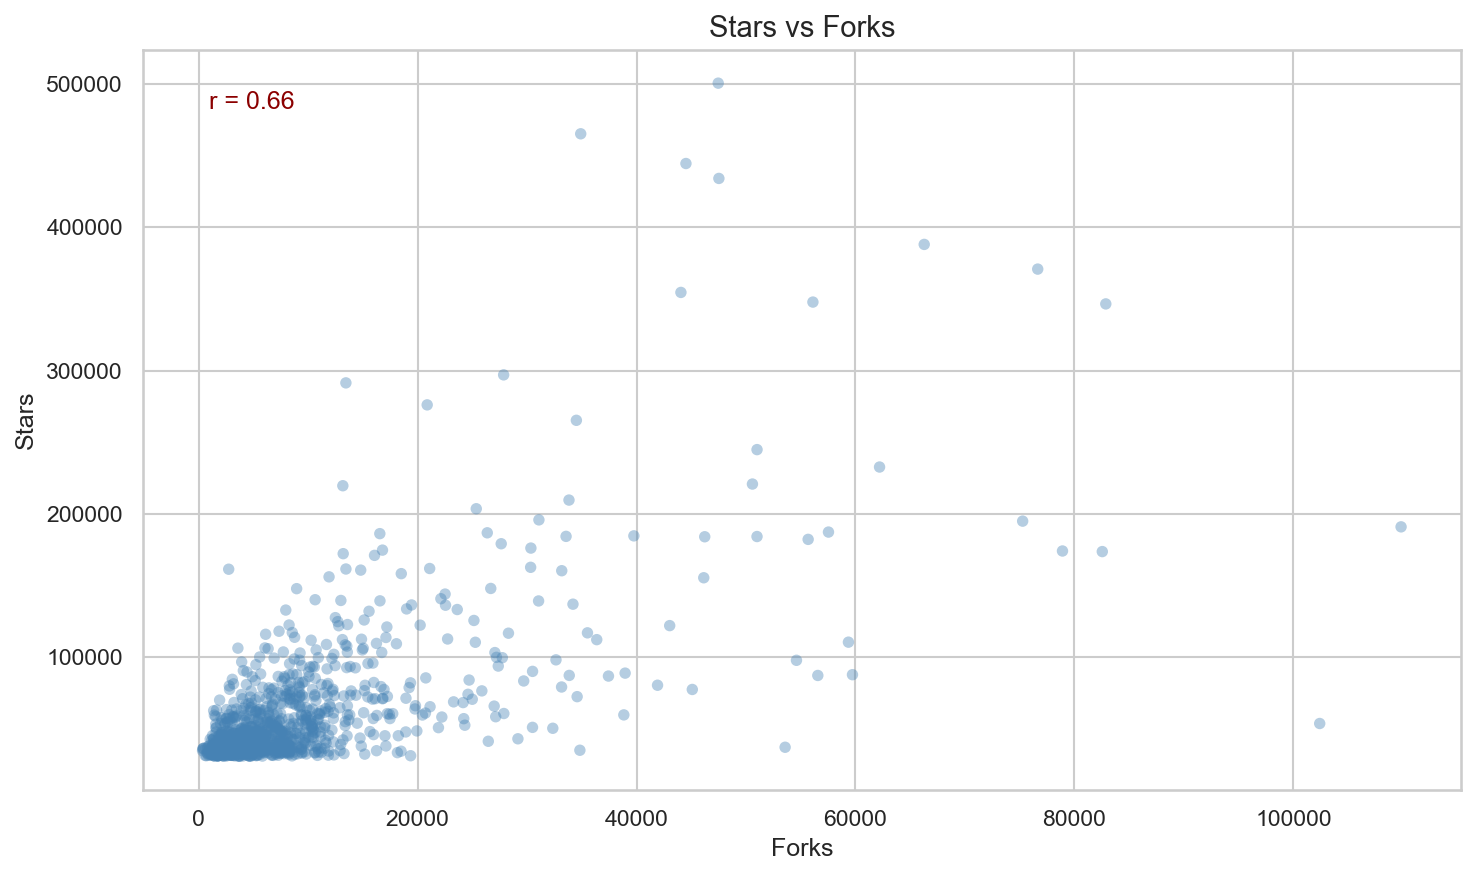

In [72]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df["forks"], 
    df["stars"],
    alpha=0.4,          # transparency so overlapping points show
    color="steelblue",
    edgecolors="none",
    s=30                # point size
)

ax.set_title("Stars vs Forks", fontsize=14)
ax.set_xlabel("Forks")
ax.set_ylabel("Stars")

# Add correlation annotation
corr_val = df["stars"].corr(df["forks"])
ax.annotate(f"r = {corr_val:.2f}", xy=(0.05, 0.92), 
            xycoords="axes fraction", fontsize=12,
            color="darkred")

plt.tight_layout()
plt.savefig("../notebooks/figures/stars_vs_forks.png")
plt.show()

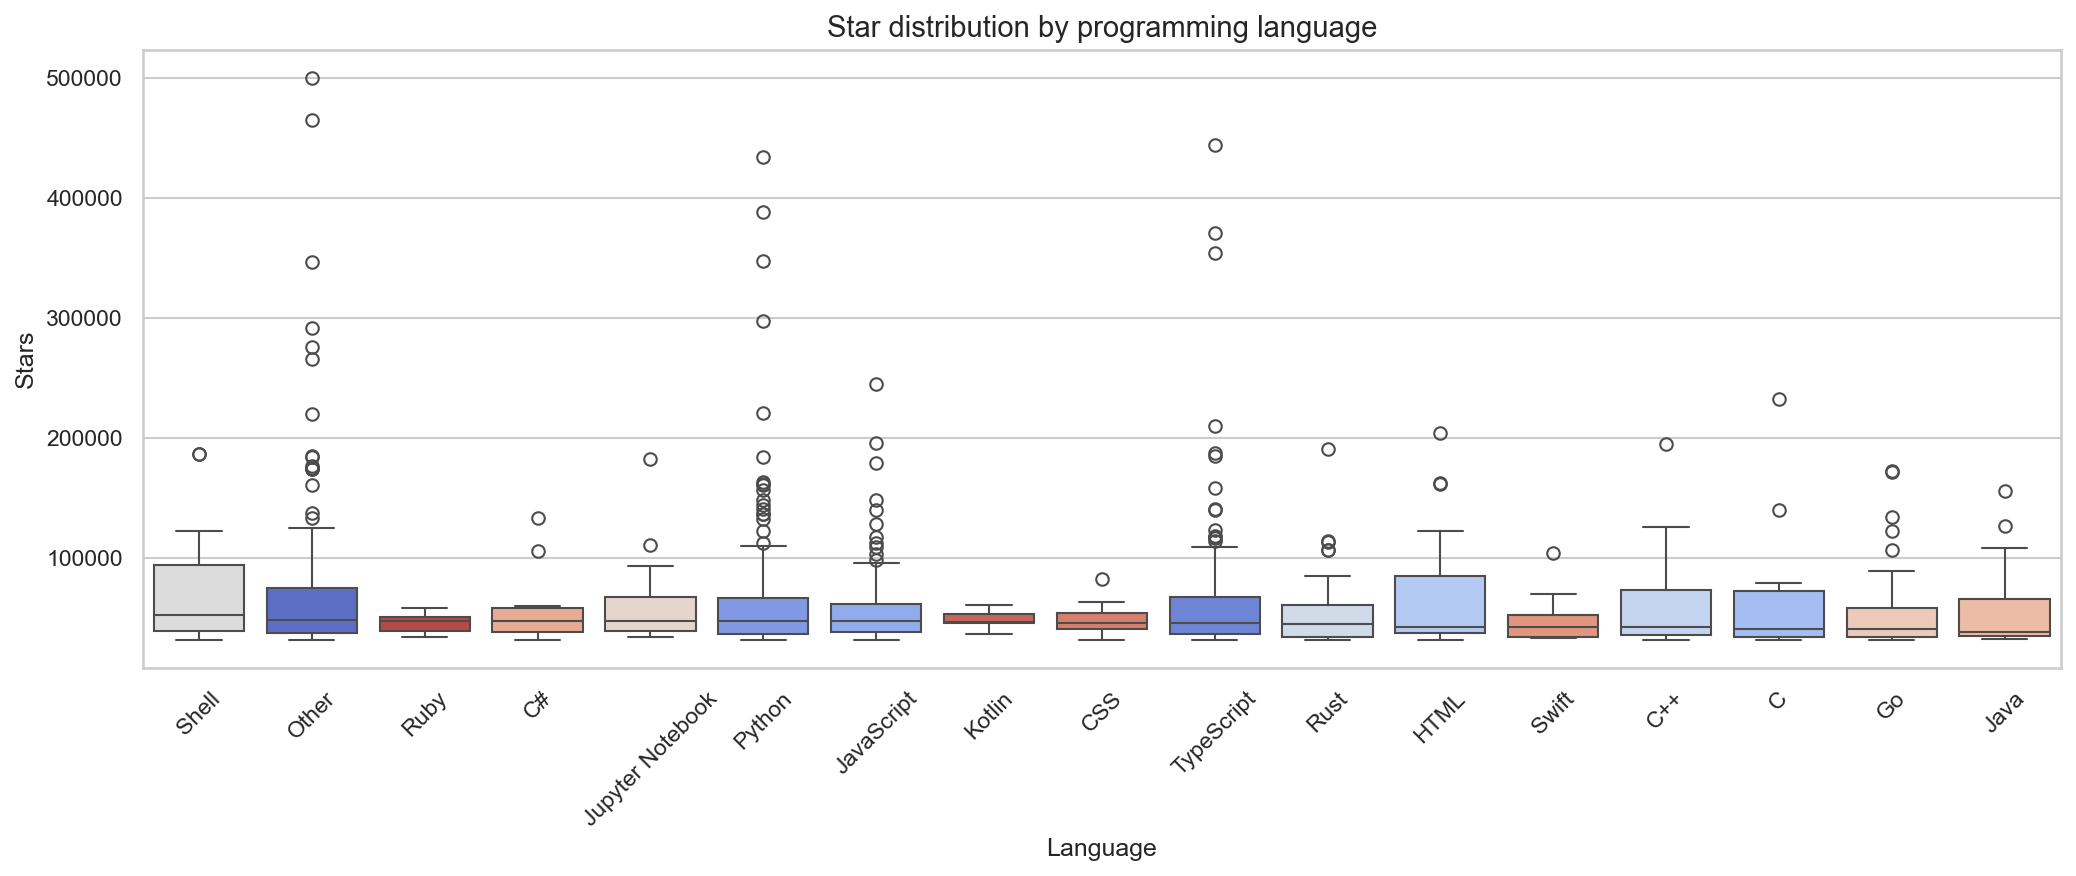

In [73]:
# Get median stars per language for ordering
lang_order = (
    df.groupby("language_grouped")["stars"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="language_grouped",
    y="stars",
    order=lang_order,
    hue="language_grouped",
    palette="coolwarm",
    ax=ax
)

ax.set_title("Star distribution by programming language", fontsize=14)
ax.set_xlabel("Language")
ax.set_ylabel("Stars")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("figures/stars_by_language.png")
plt.show()

## Sanity check on the rest of the data

In [74]:
new_cols = [
    "description", "homepage", "license", "topics",
    "has_wiki", "has_pages", "is_fork", "archived",
    "contributors", "releases", "open_pull_requests",
    "subscribers_count", "network_count"
]

print("Missing values:")
print(df[new_cols].isnull().sum())
print("\nBasic stats:")
df[["contributors", "releases", "open_pull_requests", 
    "subscribers_count", "network_count"]].describe()

Missing values:
description             7
homepage              247
license                84
topics                155
has_wiki                0
has_pages               0
is_fork                 0
archived                0
contributors            1
releases                0
open_pull_requests      5
subscribers_count       0
network_count           0
dtype: int64

Basic stats:


,contributors,releases,open_pull_requests,subscribers_count,network_count
count,999.000000,1000.000000,995.000000,1000.000000,1000.000000
mean,577.365365,148.501000,165.553769,912.266000,9413.714000
std,1288.304960,389.355035,507.137078,1158.012906,11502.677329
min,1.000000,0.000000,0.000000,0.000000,358.000000
25%,78.000000,0.000000,13.000000,254.750000,3315.750000
50%,230.000000,40.000000,45.000000,511.500000,6048.000000
75%,550.500000,146.000000,132.000000,1136.000000,10399.500000
max,22004.000000,6044.000000,7488.000000,9795.000000,109841.000000


Based on this, the null values will be filles with 0s or the median.